# 06 — HAI external scope check

**Purpose.** Ask whether recording-related differences of the kind seen on ProvICS also appear in
another OT benchmark. This is a **scope check**, not a performance comparison and not a claim
that the ProvICS effect generalises.

**Inputs**  `results/paper_tables/hai_portable_core_{full,summary}.csv`.

**Outputs**  `results/regenerated/hai_by_target_file.csv`.


In [1]:
import os, sys
from pathlib import Path
if 'google.colab' in sys.modules:
    from google.colab import drive; drive.mount('/content/drive')
    os.environ.setdefault('PROVICS_ROOT', '/content/drive/MyDrive/provics-recording-aware-evaluation')
else:
    os.environ.setdefault('PROVICS_ROOT', str(Path.cwd().parent))
sys.path.insert(0, os.environ['PROVICS_ROOT'])
from src.utils.paths import project_root
ROOT = project_root(); print('Project folder:', ROOT.name)

# Render compact, readable tables below each cell.
from IPython.display import display
import pandas as pd
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_columns', 12)
pd.set_option('display.precision', 4)


Project folder: code


In [2]:
from src.evaluation.replay import load_settings
hai = load_settings()['external_check_hai']
print('role       :', hai['role'])
for statement in hai['not']:
    print('  NOT      :', statement)
print('eligibility:', hai['eligibility'])
print('eligible   : %d of %d' % (hai['eligible_comparisons'], hai['total_comparisons']))
print('excluded   :', hai['excluded'])
print('independence:', hai['independence'])


role       : external scope check only
  NOT      : a direct performance comparison with ProvICS
  NOT      : a universal generalization claim
  NOT      : independent replication across all reference-target rows
eligibility: at least 20 attack-positive and 20 buffered non-action windows
eligible   : 12 of 15
excluded   : test1 (14 positive windows)
independence: comparisons reuse three reference files and four eligible target files


In [3]:
import pandas as pd
rows = pd.read_csv(ROOT / 'results/paper_tables/hai_portable_core_full.csv')
eligible = rows[rows.status == 'complete']
display(eligible[['reference','target','auc_cross','auc_within','delta_cw']].round(3))


,reference,target,auc_cross,auc_within,delta_cw
1,train1,test2,0.815,0.879,-0.064
2,train1,test3,0.979,0.957,0.022
3,train1,test4,0.945,0.926,0.019
4,train1,test5,0.963,0.921,0.042
6,train2,test2,0.765,0.797,-0.032
7,train2,test3,0.964,0.898,0.066
8,train2,test4,0.855,0.882,-0.027
9,train2,test5,0.906,0.876,0.030
11,train3,test2,0.896,0.862,0.034
12,train3,test3,0.991,0.979,0.012


In [4]:
# The 12 rows reuse three reference files and four target files, so they are not 12
# independent observations. Aggregating by unique target file is the honest summary.
by_target = eligible.groupby('target').agg(
    references=('reference','nunique'), cross=('auc_cross','median'),
    within=('auc_within','median'), delta_cw=('delta_cw','median'),
    delta_min=('delta_cw','min'), delta_max=('delta_cw','max')).round(3)
by_target['sign_stable'] = [bool((eligible[eligible.target==t].delta_cw > 0).all() or
                                 (eligible[eligible.target==t].delta_cw < 0).all())
                            for t in by_target.index]
display(by_target)
print('\nThe sign of Delta_CW changes with the chosen normal reference for %d of %d target files.'
      % ((~by_target.sign_stable).sum(), len(by_target)))


,references,cross,within,delta_cw,delta_min,delta_max,sign_stable
target,,,,,,,
test2,3,0.815,0.862,-0.032,-0.064,0.034,False
test3,3,0.979,0.957,0.022,0.012,0.066,True
test4,3,0.945,0.926,0.019,-0.027,0.026,False
test5,3,0.963,0.921,0.035,0.030,0.042,True



The sign of Delta_CW changes with the chosen normal reference for 2 of 4 target files.


### Reference choice can change the sign

Each line is one of the existing normal-reference files. The points reuse four target files, so they are dependent settings, not twelve independent experiments.


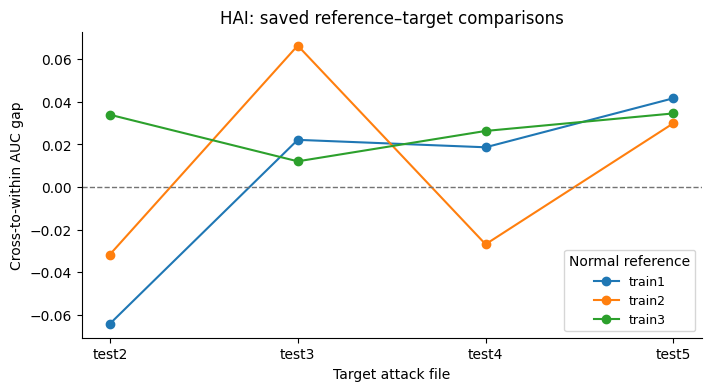

In [5]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 3.8), layout='constrained')
for reference, block in eligible.groupby('reference'):
    block = block.sort_values('target')
    ax.plot(block.target, block.delta_cw, 'o-', label=reference)
ax.axhline(0, color='0.45', linewidth=1, linestyle='--')
ax.set(xlabel='Target attack file', ylabel='Cross-to-within AUC gap',
       title='HAI: saved reference–target comparisons')
ax.legend(title='Normal reference', fontsize=9)
ax.spines[['top', 'right']].set_visible(False)
plt.show()
plt.close(fig)

In [6]:
# Scale comparison, stated qualitatively because the datasets differ in representation.
provics = pd.read_csv(ROOT / 'results/paper_tables/window_sensitivity_summary.csv')
provics_gap = provics.groupby(['window_s','modality']).delta_cw.mean()
print('ProvICS Delta_CW  : %+.3f to %+.3f' % (provics_gap.min(), provics_gap.max()))
print('HAI     Delta_CW  : %+.3f to %+.3f (per target-file median)'
      % (by_target.delta_cw.min(), by_target.delta_cw.max()))
print()
print('HAI shows smaller and reference-dependent recording sensitivity. That establishes',
      'neither a universal direction nor a universal magnitude: the quantity is dataset- and',
      'reference-dependent and should be measured explicitly rather than assumed.')

out = ROOT / 'results/regenerated'; out.mkdir(parents=True, exist_ok=True)
by_target.to_csv(out / 'hai_by_target_file.csv')
print('\nwrote results/regenerated/hai_by_target_file.csv')


ProvICS Delta_CW  : +0.149 to +0.535
HAI     Delta_CW  : -0.032 to +0.035 (per target-file median)

HAI shows smaller and reference-dependent recording sensitivity. That establishes neither a universal direction nor a universal magnitude: the quantity is dataset- and reference-dependent and should be measured explicitly rather than assumed.

wrote results/regenerated/hai_by_target_file.csv


## What this notebook established

- 12 of 15 HAI reference-target comparisons met the eligibility rule; test1 was excluded for support.
- Recording sensitivity on HAI is smaller than on ProvICS and changes sign with the chosen reference.
- The rows share source files and are not independent replications.
- No claim is made that the ProvICS effect is universal across OT benchmarks.
